In [1]:
import pandas as pd
import random
import pickle
import torch.nn as nn
import torch
import torch.nn.functional as F
import numpy as np
from sb import model
from sklearn.preprocessing import MinMaxScaler
from visualize import *
from data_generation import *   
from preprocessing import *
from loss import *
import math

seed = 420
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

100%|██████████| 1/1 [00:00<00:00, 196.16it/s]


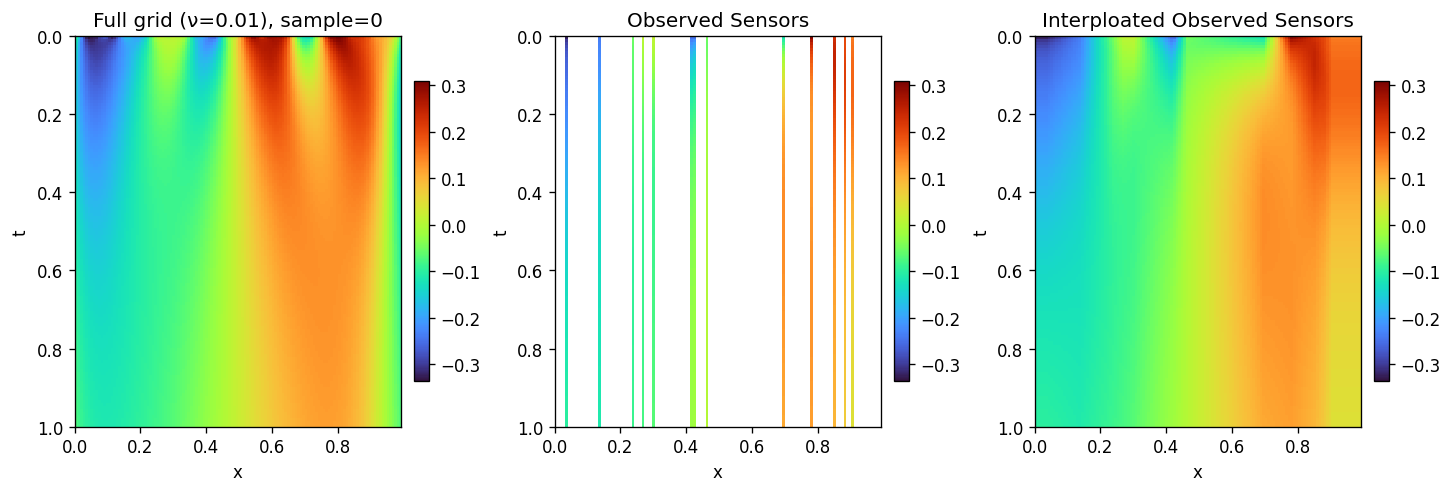

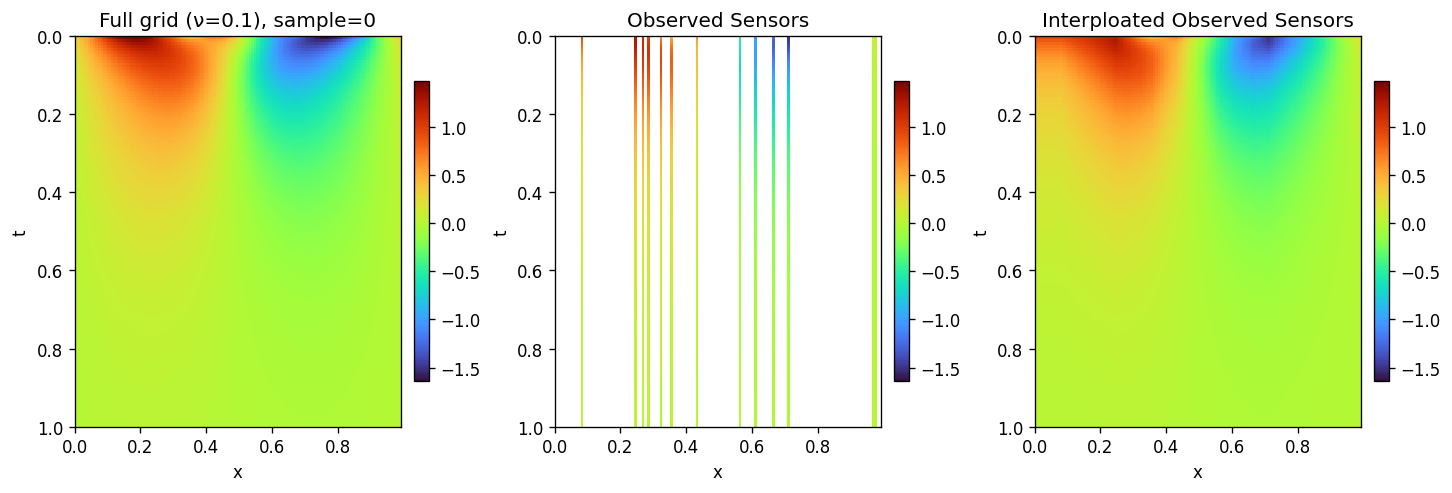

In [2]:
high_resol_coef = 0.01
low_resol_coef = 0.1

data1 = generate_dataset(
    n_samples=1,
    nu=high_resol_coef,    
    Nx=128,    
    Nt=128, 
    T=1.0,
    L=1.0,
    grf_type="periodic",
    n_sensors=13,
    fixed_sensors=True,
    seed=0,
)
data2 = generate_dataset(
    n_samples=1,
    nu=low_resol_coef,    
    Nx=128,    
    Nt=128, 
    T=1.0,
    L=1.0,
    grf_type="periodic",
    n_sensors=13,
    fixed_sensors=True,
    seed=20,
)
data1 = fill_missing_with_linear_interp(data1)
data2 = fill_missing_with_linear_interp(data2)
plot_full_and_observed_heatmaps(data1, sample_idx=0)
plot_full_and_observed_heatmaps(data2, sample_idx=0)

In [3]:
((np.abs(data2['U_full'] - data2['U_filled']))**2).mean()

0.002355657

In [4]:
WA, WB, starts = make_paired_time_window_dataset(
    data1, # full grid 줄 친구
    data2, # 일부 센서만 줄 친구
    win_T=128,
    stride=128,
    start_t=0,
    end_t=None,
)
print(burgers_pde_mse(torch.tensor(data1['U_full']), high_resol_coef), burgers_pde_mse(torch.tensor(data2['U_full']), low_resol_coef))
print(burgers_pde_mse(torch.tensor(data2['U_filled']), low_resol_coef))
sensor_mask = torch.from_numpy(data2["mask"]).float()
sensor_mask = sensor_mask.view(1, 1, 1, -1)
WB_mask = sensor_mask.repeat(WB.shape[0], 1, WB.shape[2], 1)
mask_list = [None, WB_mask]

print(WA.shape, WB.shape)

WA_scaled, WB_scaled = flatten(WA, WB)
print(WA_scaled.shape, WB_scaled.shape)
# WA_scaled *= 3
# WB_scaled *= 10
# WA *= 3
# WB *= 10

tensor(0.0007) tensor(0.0137)
tensor(28.2380)
torch.Size([1, 1, 128, 128]) torch.Size([1, 1, 128, 128])
torch.Size([1, 16384]) torch.Size([1, 16384])


In [ ]:
steps = 10
eps_train = 0.01
eps_test = 0.01
sb_object = model.sb_muti_model([WA, WB],[0,1],N_train=300, base_lr=1e-4,
                              steps=steps,eps_train=eps_train,eps_test=eps_test,patience=500,B=WA_scaled.shape[0],lambda_=1e-3,clamp=False,save=True, mask_list=mask_list)


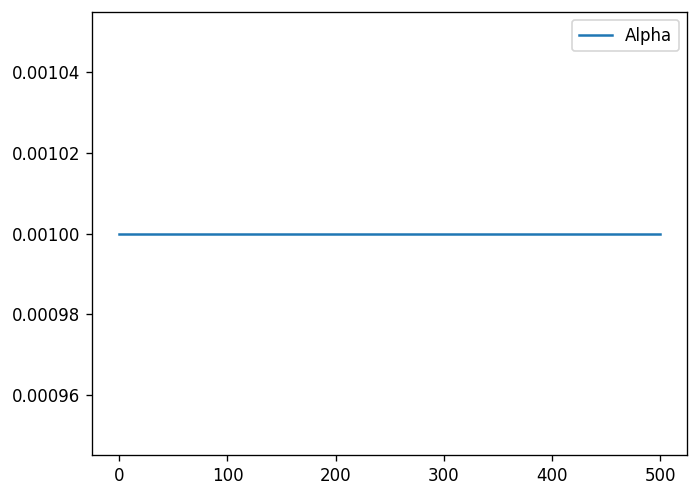

processed: 529:   2%|▏         | 529/30000 [00:17<16:00, 30.69it/s, MSE_observed=0.061995994, PDE_loss=4.846757, PDE_loss2=1.7038658, Alpha=0.0009999999] 


KeyboardInterrupt: 

In [6]:
sb_object.train()

In [ ]:
sb_object.finetuning_load('model/finetuning_end.pt')

In [7]:
# eps_test = 0.01
# sb_object.steps = 60
predict = sb_object.eval_fore(x_0 = WA_scaled, x_1_fixed = (WB * WB_mask), mask=WB_mask, eps_test=0)
predict = predict[-1].detach().cpu().numpy()
predict = torch.from_numpy(predict)
predict = stitch_windows(predict, starts, win_T=128, Nx=128, stride=128)
data2_predict_initial = generate_dataset_predict_initial(
    n_samples=1,
    nu=sb_object.alpha.to('cpu').detach().numpy(),    
    Nx=128,    
    Nt=128, 
    T=1.0,
    L=1.0,
    predict=predict,
    n_sensors=2,
    fixed_sensors=True,
    seed=20,
)

  0%|          | 0/1 [00:00<?, ?it/s]/home/chan/PISB/PI-BRIDGE/data_generation.py:177: RuntimeWarning: overflow encountered in multiply
  u2_hat = np.fft.fft(u * u)
/home/chan/PISB/PI-BRIDGE/data_generation.py:178: RuntimeWarning: invalid value encountered in multiply
  u2_hat *= mask  # dealias
/home/chan/PISB/PI-BRIDGE/data_generation.py:179: RuntimeWarning: invalid value encountered in multiply
  return -0.5j * k * u2_hat
/home/chan/PISB/PI-BRIDGE/data_generation.py:220: RuntimeWarning: overflow encountered in cast
  return U.astype(np.float32)
100%|██████████| 1/1 [00:00<00:00, 160.46it/s]


In [8]:
print("All pixel MSE :", (np.abs(data2['U_full'].squeeze(0).squeeze(0) - predict.detach().cpu().numpy())**2).mean())
print("Observed pixel MSE :", (np.abs(data2['U_full'].squeeze(0).squeeze(0)[:, data2['mask']] - predict.detach().cpu().numpy()[:, data2['mask']])**2).mean())
print("All pixel PDE (True alpha):", burgers_pde_mse(predict.unsqueeze(0).unsqueeze(0), low_resol_coef))
print("All pixel PDE (Estimated alpha) :", burgers_pde_mse(predict.unsqueeze(0).unsqueeze(0), sb_object.alpha.to('cpu')))
print("Observed pixel PDE (True alpha) :", burgers_pde_mse_observed_pixel(predict.unsqueeze(0).unsqueeze(0), low_resol_coef, WB_mask))
print("Observed pixel PDE (Estimated alpha) :", burgers_pde_mse_observed_pixel(predict.unsqueeze(0).unsqueeze(0), sb_object.alpha.to('cpu'), WB_mask))

All pixel MSE : 0.045644633
Observed pixel MSE : 0.0
All pixel PDE (True alpha): tensor(12842.5654)
All pixel PDE (Estimated alpha) : tensor(9.1712, grad_fn=<MeanBackward0>)
Observed pixel PDE (True alpha) : tensor(175.0370)
Observed pixel PDE (Estimated alpha) : tensor(3.6054, grad_fn=<DivBackward0>)


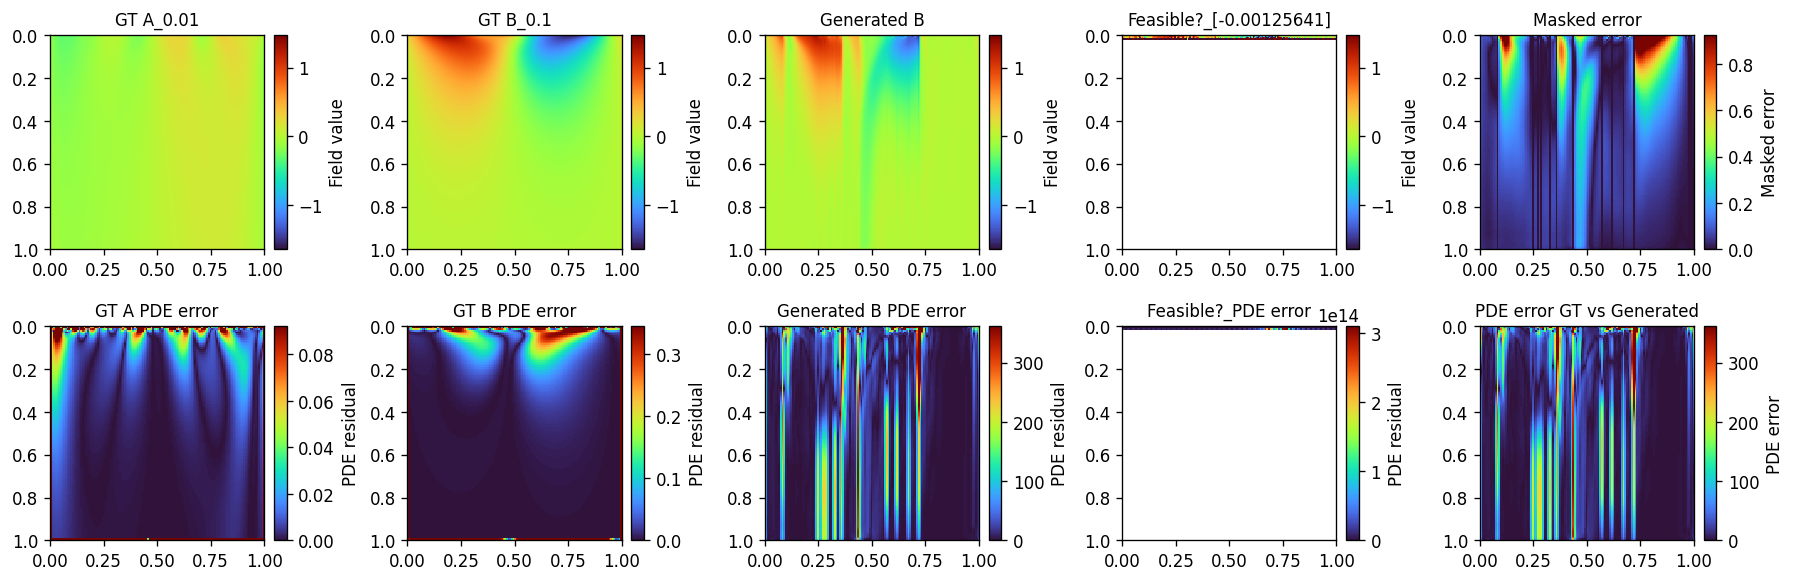

In [9]:
plot_result(
    data1['U_full'],
    data2['U_full'],
    data2_predict_initial['U_full'],
    predict,
    cmap="turbo",
    high_resol_coef=high_resol_coef,
    low_resol_coef=low_resol_coef,
    estimated_coef=sb_object.alpha.to('cpu')
)

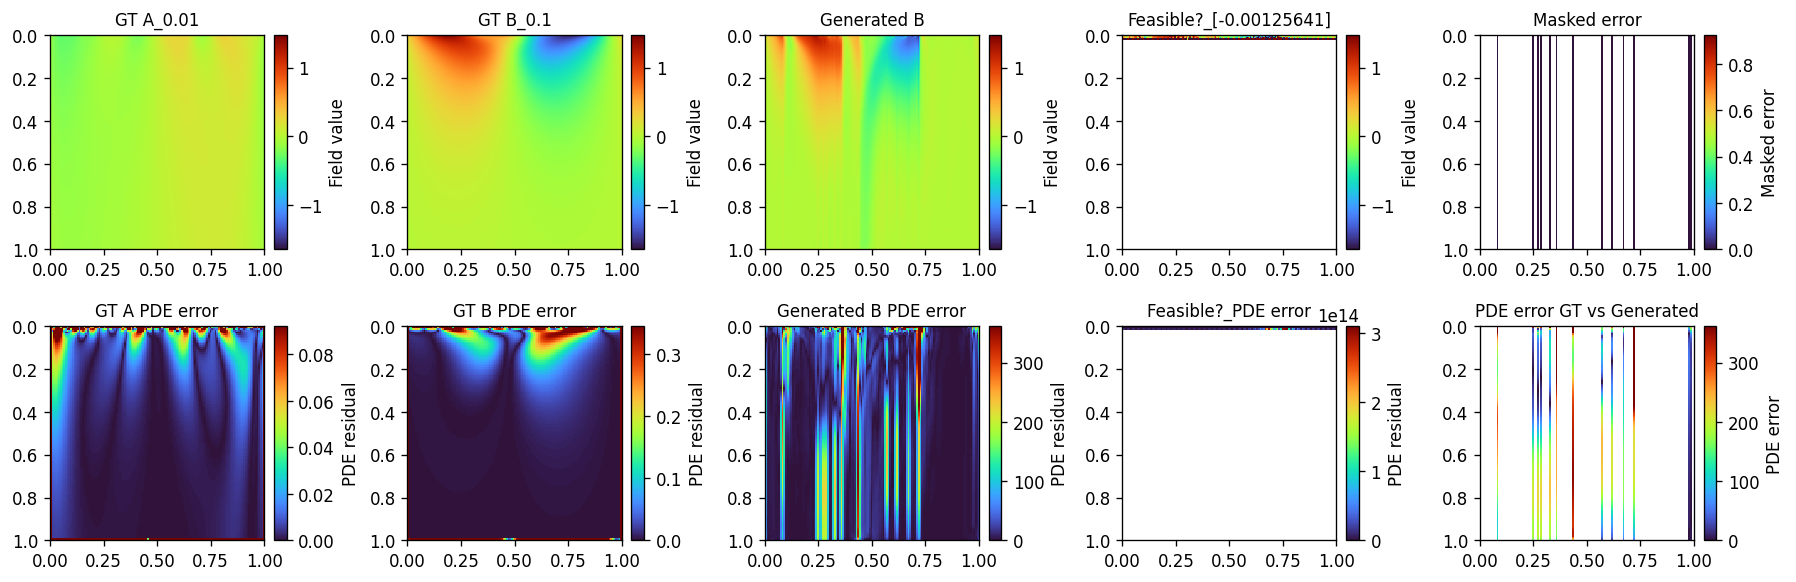

In [10]:
plot_result(
    data1['U_full'],
    data2['U_full'],
    data2_predict_initial['U_full'],
    predict,
    cmap="turbo",
    high_resol_coef=high_resol_coef,
    low_resol_coef=low_resol_coef,
    estimated_coef=sb_object.alpha.to('cpu'),
    mask_1d=data2['mask']
)